In [ ]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
import torch

from tianshou.env import DummyVectorEnv
from tianshou.data import Collector, VectorReplayBuffer, PrioritizedVectorReplayBuffer
from tianshou.utils.net.common import Net
from tianshou.algorithm.modelfree.dqn import DQN, DiscreteQLearningPolicy
from tianshou.algorithm.optim import AdamOptimizerFactory
from tianshou.algorithm.algorithm_base import policy_within_training_step

In [ ]:
# ── Constants ─────────────────────────────────────────────────────────────────

SEED         = 42
N_EPOCHS     = 30
N_EVAL_ENVS  = 20   # parallel envs for eval at each epoch checkpoint
N_TRAIN_ENVS = 4    # parallel envs during training

ENVS = {
    "CartPole-v1":    dict(total_steps= 50_000),
    "Acrobot-v1":     dict(total_steps=150_000),
    "MountainCar-v0": dict(total_steps=400_000),
    "Taxi-v3":        dict(total_steps=400_000),
}

# ── Shared hyperparams — identical for both models in every section ───────────
# Chosen to mirror CV.ipynb SB3 settings as closely as possible.

HIDDEN_SIZES     = [128, 128]
LR               = 1e-4
BATCH_SIZE       = 64
GAMMA            = 0.99
BUFFER_SIZE      = 50_000
TARGET_UPDATE    = 1_000   # gradient steps between target network soft updates
LEARNING_STARTS  = 1_000   # steps before any gradient update
TRAIN_FREQ       = 4       # collect this many steps between gradient updates
GRADIENT_STEPS   = 1       # gradient steps per train_freq block
EPS_START        = 1.0
EPS_END          = 0.05
EPS_FRAC         = 0.15    # fraction of total_steps to anneal eps over


# ── Taxi-v3 observation wrapper ───────────────────────────────────────────────
# Taxi-v3 has a Discrete(500) obs.  Tianshou Net expects a float array.
# We encode the obs as a single normalised float.

class TaxiObs(gym.ObservationWrapper):
    def __init__(self, env):
        super().__init__(env)
        n = env.observation_space.n
        self._n = n
        self.observation_space = gym.spaces.Box(
            low=0.0, high=1.0, shape=(1,), dtype=np.float32
        )
    def observation(self, obs):
        return np.array([obs / self._n], dtype=np.float32)


def _make_env(env_id):
    env = gym.make(env_id)
    if env_id == "Taxi-v3":
        env = TaxiObs(env)
    return env


# ── Training object factory ────────────────────────────────────────────────────

def make_objects(
    env_id,
    *,
    is_double  = False,
    dueling    = False,
    n_step     = 1,
    per_alpha  = None,      # None = uniform buffer; float = PER
    per_beta   = 0.4,
    seed       = SEED,
):
    """
    Creates and returns:
      dqn, buffer, train_col, eval_col

    Toggle components via keyword args — all other hyperparams come from globals.
    """
    torch.manual_seed(seed)

    # Environments
    train_envs = DummyVectorEnv([lambda eid=env_id: _make_env(eid)] * N_TRAIN_ENVS)
    eval_envs  = DummyVectorEnv([lambda eid=env_id: _make_env(eid)] * N_EVAL_ENVS)

    obs_shape = train_envs.observation_space[0].shape  # e.g. (4,) for CartPole
    n_actions = train_envs.action_space[0].n

    # Network
    dueling_param = ({}, {}) if dueling else None   # empty heads = Linear after trunk
    net = Net(
        state_shape    = obs_shape,
        action_shape   = n_actions,
        hidden_sizes   = HIDDEN_SIZES,
        dueling_param  = dueling_param,
    )

    # Policy + algorithm
    policy = DiscreteQLearningPolicy(
        model              = net,
        action_space       = train_envs.action_space[0],
        observation_space  = train_envs.observation_space[0],
        eps_training       = EPS_START,
        eps_inference      = 0.0,
    )
    dqn = DQN(
        policy                = policy,
        optim                 = AdamOptimizerFactory(lr=LR),
        gamma                 = GAMMA,
        n_step_return_horizon = n_step,
        target_update_freq    = TARGET_UPDATE,
        is_double             = is_double,
        huber_loss_delta      = 1.0,    # Huber loss (matches SB3 smooth_l1)
    )

    # Replay buffer
    if per_alpha is not None:
        buffer = PrioritizedVectorReplayBuffer(
            total_size = BUFFER_SIZE,
            buffer_num = N_TRAIN_ENVS,
            alpha      = per_alpha,
            beta       = per_beta,
        )
    else:
        buffer = VectorReplayBuffer(
            total_size = BUFFER_SIZE,
            buffer_num = N_TRAIN_ENVS,
        )

    train_col = Collector(policy=dqn, env=train_envs, buffer=buffer)
    eval_col  = Collector(policy=dqn, env=eval_envs)

    return dqn, buffer, train_col, eval_col


# ── Training helper ───────────────────────────────────────────────────────────

def train_epochs_ts(dqn, buffer, train_col, eval_col, env_id, total_steps,
                    invariant_fn=None):
    """
    Train for N_EPOCHS equal intervals.  Eval after each epoch with N_EVAL_ENVS.
    Returns (rewards, invariants).

    Epsilon annealing: linear from EPS_START to EPS_END over EPS_FRAC * total_steps.
    Training starts only after LEARNING_STARTS steps in the buffer.
    Gradient update frequency: GRADIENT_STEPS updates per TRAIN_FREQ collected steps.
    """
    steps_per_epoch = max(1, total_steps // N_EPOCHS)
    anneal_steps    = max(1, int(EPS_FRAC * total_steps))

    rewards, invariants = [], []
    total_collected = 0

    train_col.reset()

    for epoch in range(N_EPOCHS):
        # ── collect ───────────────────────────────────────────────────────────
        result = train_col.collect(n_step=steps_per_epoch)
        total_collected += result.n_collected_steps

        # ── anneal epsilon ────────────────────────────────────────────────────
        frac = min(1.0, total_collected / anneal_steps)
        eps  = EPS_START + frac * (EPS_END - EPS_START)
        dqn.policy.set_eps_training(eps)

        # ── gradient updates ──────────────────────────────────────────────────
        if len(buffer) >= LEARNING_STARTS:
            n_updates = max(1, steps_per_epoch // TRAIN_FREQ) * GRADIENT_STEPS
            with policy_within_training_step(dqn.policy):
                for _ in range(n_updates):
                    dqn.update(buffer=buffer, sample_size=BATCH_SIZE)

        # ── eval ──────────────────────────────────────────────────────────────
        eval_col.reset()
        eval_result = eval_col.collect(n_episode=N_EVAL_ENVS)
        rewards.append(eval_result.returns_stat.mean)

        if invariant_fn is not None:
            invariants.append(invariant_fn(dqn, buffer))

    train_col.env.close()
    eval_col.env.close()
    return rewards, invariants


# ── Plotting helper (identical API to CV.ipynb) ───────────────────────────────

def _smooth(arr, w):
    """Centred rolling mean with window w; edges use available data (no padding)."""
    arr = np.asarray(arr, dtype=float)
    out = np.full_like(arr, np.nan)
    half = w // 2
    for i in range(len(arr)):
        lo = max(0, i - half)
        hi = min(len(arr), i + half + 1)
        out[i] = arr[lo:hi].mean()
    return out


def plot_section(title, env_results, label_a, label_b,
                 inv_label=None, colors=("steelblue", "orangered"), smooth=5):
    """
    env_results: list of dicts with env_id, rewards_a, rewards_b,
                 and optionally invs_a, invs_b.

    smooth: rolling-window width for the solid overlay (raw data shown faint).
            Set to 1 or None to disable.
    """
    has_inv = inv_label is not None and "invs_a" in env_results[0]
    n_cols  = 2 if has_inv else 1
    fig, axes = plt.subplots(
        len(env_results), n_cols,
        figsize=(6 * n_cols, 3.2 * len(env_results)),
        squeeze=False,
    )
    fig.suptitle(title, fontsize=13, fontweight="bold")
    w = smooth if (smooth and smooth > 1) else None

    for row, res in enumerate(env_results):
        env_id = res["env_id"]
        steps  = (np.arange(1, N_EPOCHS + 1)
                  * (ENVS[env_id]["total_steps"] // N_EPOCHS))

        def _plot(ax, ya, yb, ylabel):
            if w:
                ax.plot(steps, ya, alpha=0.2, color=colors[0], lw=1)
                ax.plot(steps, yb, alpha=0.2, color=colors[1], lw=1)
                ax.plot(steps, _smooth(ya, w), label=label_a, color=colors[0], lw=2)
                ax.plot(steps, _smooth(yb, w), label=label_b, color=colors[1], lw=2)
            else:
                ax.plot(steps, ya, label=label_a, color=colors[0], lw=2)
                ax.plot(steps, yb, label=label_b, color=colors[1], lw=2)
            ax.set_ylabel(ylabel)
            ax.legend(fontsize=8)
            ax.grid(True, alpha=0.3)

        ax = axes[row, 0]
        _plot(ax, res["rewards_a"], res["rewards_b"], "Mean reward")
        ax.set_title(env_id)
        if row == len(env_results) - 1:
            ax.set_xlabel("Env steps")

        if has_inv:
            ax2 = axes[row, 1]
            _plot(ax2, res["invs_a"], res["invs_b"], inv_label)
            ax2.set_title(f"{env_id}  —  {inv_label}")
            if row == len(env_results) - 1:
                ax2.set_xlabel("Env steps")

    plt.tight_layout()
    plt.show()


# ── Invariant functions ────────────────────────────────────────────────────────
# Each takes (dqn, buffer) and returns a scalar float.

def _sample_batch(buffer, size=512):
    """Sample a Batch from the buffer; None if not enough data."""
    if len(buffer) < size:
        return None
    batch, _ = buffer.sample(size)
    return batch


def inv_overestimation_gap(dqn, buffer):
    """
    Double DQN — E[max_a Q_target(s')] − E[Q_target(s', argmax Q_online(s'))].
    Standard DQN: positive (online net overestimates).
    Double DQN: near zero (decoupled selection/evaluation).
    """
    batch = _sample_batch(buffer)
    if batch is None:
        return float("nan")
    obs_next = torch.as_tensor(batch.obs_next, dtype=torch.float32)
    with torch.no_grad():
        # Online net: policy.model
        q_on, _  = dqn.policy.model(obs_next)
        # Target net: model_old wraps the same architecture
        q_tg, _  = dqn.model_old(obs_next)
    naive  = q_tg.max(dim=1).values.mean().item()
    double = q_tg.gather(1, q_on.argmax(dim=1, keepdim=True)).squeeze(1).mean().item()
    return naive - double


def inv_advantage_std(dqn, buffer):
    """
    Dueling — mean std of A(s,a) across actions.
    A(s,a) = Q(s,a) − mean_a Q(s,a)  (identical for dueling and standard net).
    Dueling decomposes V and A explicitly, freeing the scale of A.
    """
    batch = _sample_batch(buffer)
    if batch is None:
        return float("nan")
    obs = torch.as_tensor(batch.obs, dtype=torch.float32)
    with torch.no_grad():
        q, _ = dqn.policy.model(obs)
    adv = q - q.mean(dim=1, keepdim=True)
    return adv.std(dim=1).mean().item()


def inv_priority_cv(dqn, buffer):
    """
    PER — coefficient of variation of leaf priorities in the SegmentTree.
    CV = std / mean.  0 = uniform; grows as PER focuses on high-TD transitions.

    PrioritizedVectorReplayBuffer maintains one shared SegmentTree (buffer.weight)
    on the manager object.  Active entries have weight > 0; empty slots are 0.
    """
    if not isinstance(buffer, PrioritizedVectorReplayBuffer):
        return float("nan")
    leaves = buffer.weight[np.arange(buffer.maxsize)]
    leaves = leaves[leaves > 0]
    if len(leaves) < 2:
        return 0.0
    return float(leaves.std() / leaves.mean())


def inv_mean_abs_reward(dqn, buffer):
    """
    n-step — mean |reward| in replay buffer.
    n-step accumulates r_t + γr_{t+1} + … so this grows vs 1-step.
    Note: tianshou stores raw single-step rewards; n-step accumulation happens
    inside compute_nstep_return at sample time during update().
    For constant-sign reward envs the ratio effect is visible in Q-value growth
    rather than raw buffer rewards.
    """
    n = len(buffer)
    if n == 0:
        return float("nan")
    data = buffer[:n]
    return float(np.abs(data.rew).mean())

  CartPole-v1 ... 

/home/arthur/anaconda3_2026/lib/python3.13/site-packages/tianshou/data/collector.py:539: UserWarning: n_step=1666 is not a multiple of (self.env_num=4), which may cause extra transitions being collected into the buffer.
  warnings.warn(


done
  Acrobot-v1 ... done
  MountainCar-v0 ... 

/home/arthur/anaconda3_2026/lib/python3.13/site-packages/tianshou/data/collector.py:539: UserWarning: n_step=13333 is not a multiple of (self.env_num=4), which may cause extra transitions being collected into the buffer.
  warnings.warn(


done
  Taxi-v3 ... done


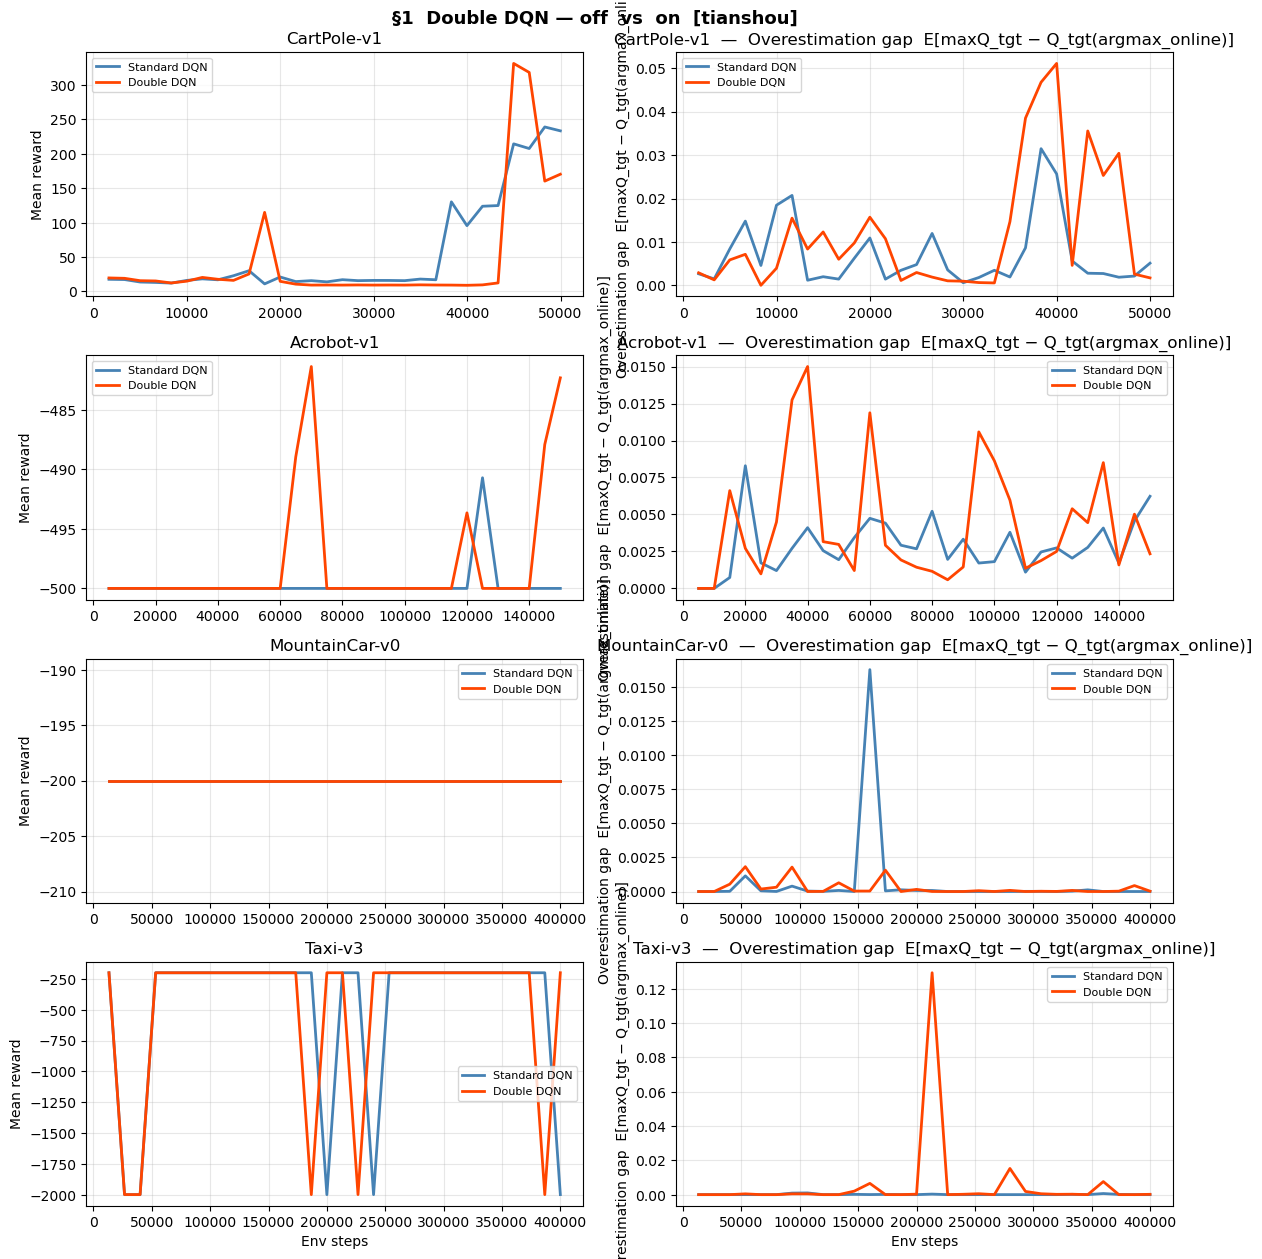

In [3]:
# ══════════════════════════════════════════════════════════════════════════════
# §1  DOUBLE DQN
# ══════════════════════════════════════════════════════════════════════════════
# Toggle: is_double=False  vs  is_double=True.  All else identical.
#
# Invariant (van Hasselt 2016):
#   gap = E[max_a Q_target(s')] − E[Q_target(s', argmax Q_online(s'))]
#   Standard DQN: gap > 0  (online net overestimates bootstrap target)
#   Double DQN:   gap ≈ 0  (decoupled selection/evaluation kills the bias)
#
# Expected: reward curves similar or better for Double DQN; gap clearly lower.

env_results = []
for env_id, meta in ENVS.items():
    print(f"  {env_id} ...", end=" ", flush=True)

    dqn_a, buf_a, tc_a, ec_a = make_objects(env_id, is_double=False, seed=SEED)
    dqn_b, buf_b, tc_b, ec_b = make_objects(env_id, is_double=True,  seed=SEED)

    rew_a, inv_a = train_epochs_ts(dqn_a, buf_a, tc_a, ec_a, env_id,
                                   meta["total_steps"], inv_overestimation_gap)
    rew_b, inv_b = train_epochs_ts(dqn_b, buf_b, tc_b, ec_b, env_id,
                                   meta["total_steps"], inv_overestimation_gap)

    env_results.append(dict(env_id=env_id,
                            rewards_a=rew_a, rewards_b=rew_b,
                            invs_a=inv_a,    invs_b=inv_b))
    print("done")

plot_section(
    "§1  Double DQN — off  vs  on  [tianshou]",
    env_results,
    label_a   = "Standard DQN",
    label_b   = "Double DQN",
    inv_label = "Overestimation gap  E[maxQ_tgt − Q_tgt(argmax_online)]",
)

  CartPole-v1 ... done
  Acrobot-v1 ... done
  MountainCar-v0 ... done
  Taxi-v3 ... done


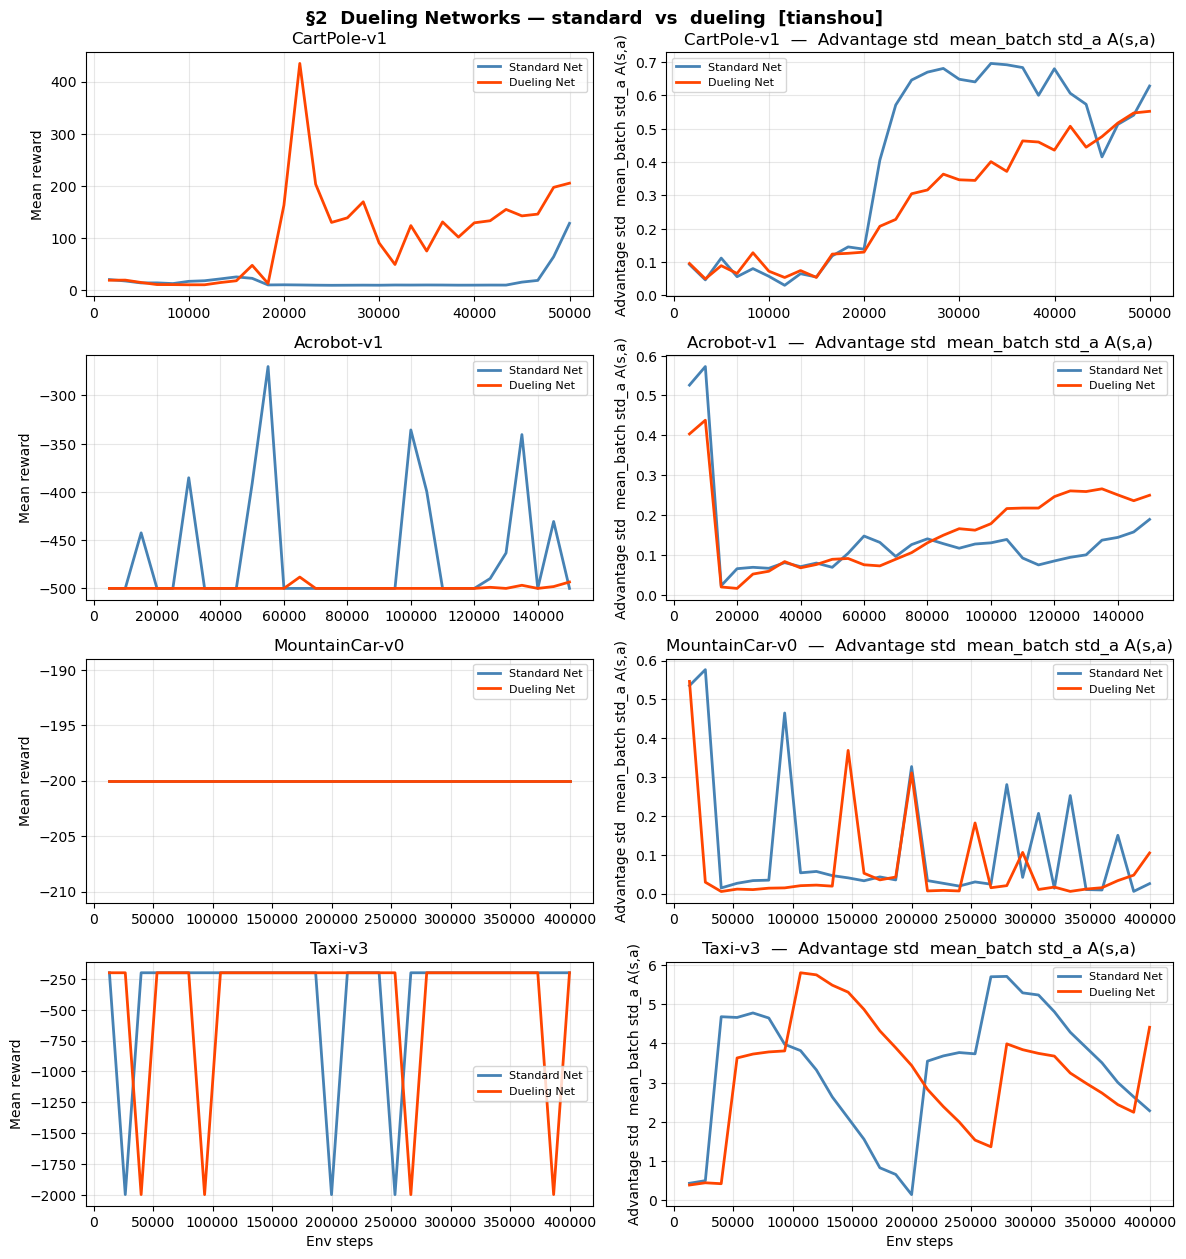

In [4]:
# ══════════════════════════════════════════════════════════════════════════════
# §2  DUELING NETWORKS
# ══════════════════════════════════════════════════════════════════════════════
# Toggle: dueling=False  vs  dueling=True.  All else identical.
#
# Tianshou: Net(dueling_param=({}, {})) appends separate V and A linear heads
# after the shared trunk, combining as Q = V + A − mean(A).
#
# Invariant (Wang et al. 2016):
#   std_A = mean_batch std_a A(s,a)   where A = Q − mean_a Q
#   Dueling explicitly learns V(s) and A(s,a) in separate heads.
#   V/A decomposition frees the scale of A → std_A can grow larger.
#
# Expected: comparable/better reward on envs with irrelevant states;
#   advantage std may differ between architectures.

env_results = []
for env_id, meta in ENVS.items():
    print(f"  {env_id} ...", end=" ", flush=True)

    dqn_a, buf_a, tc_a, ec_a = make_objects(env_id, dueling=False, seed=SEED)
    dqn_b, buf_b, tc_b, ec_b = make_objects(env_id, dueling=True,  seed=SEED)

    rew_a, inv_a = train_epochs_ts(dqn_a, buf_a, tc_a, ec_a, env_id,
                                   meta["total_steps"], inv_advantage_std)
    rew_b, inv_b = train_epochs_ts(dqn_b, buf_b, tc_b, ec_b, env_id,
                                   meta["total_steps"], inv_advantage_std)

    env_results.append(dict(env_id=env_id,
                            rewards_a=rew_a, rewards_b=rew_b,
                            invs_a=inv_a,    invs_b=inv_b))
    print("done")

plot_section(
    "§2  Dueling Networks — standard  vs  dueling  [tianshou]",
    env_results,
    label_a   = "Standard Net",
    label_b   = "Dueling Net",
    inv_label = "Advantage std  mean_batch std_a A(s,a)",
)

  CartPole-v1 ... 

/home/arthur/anaconda3_2026/lib/python3.13/site-packages/tianshou/data/collector.py:539: UserWarning: n_step=1666 is not a multiple of (self.env_num=4), which may cause extra transitions being collected into the buffer.
  warnings.warn(
/home/arthur/anaconda3_2026/lib/python3.13/site-packages/tianshou/data/collector.py:539: UserWarning: n_step=1666 is not a multiple of (self.env_num=4), which may cause extra transitions being collected into the buffer.
  warnings.warn(
/home/arthur/anaconda3_2026/lib/python3.13/site-packages/tianshou/data/collector.py:539: UserWarning: n_step=1666 is not a multiple of (self.env_num=4), which may cause extra transitions being collected into the buffer.
  warnings.warn(


done
  Acrobot-v1 ... done
  MountainCar-v0 ... 

/home/arthur/anaconda3_2026/lib/python3.13/site-packages/tianshou/data/collector.py:539: UserWarning: n_step=13333 is not a multiple of (self.env_num=4), which may cause extra transitions being collected into the buffer.
  warnings.warn(


done
  Taxi-v3 ... done


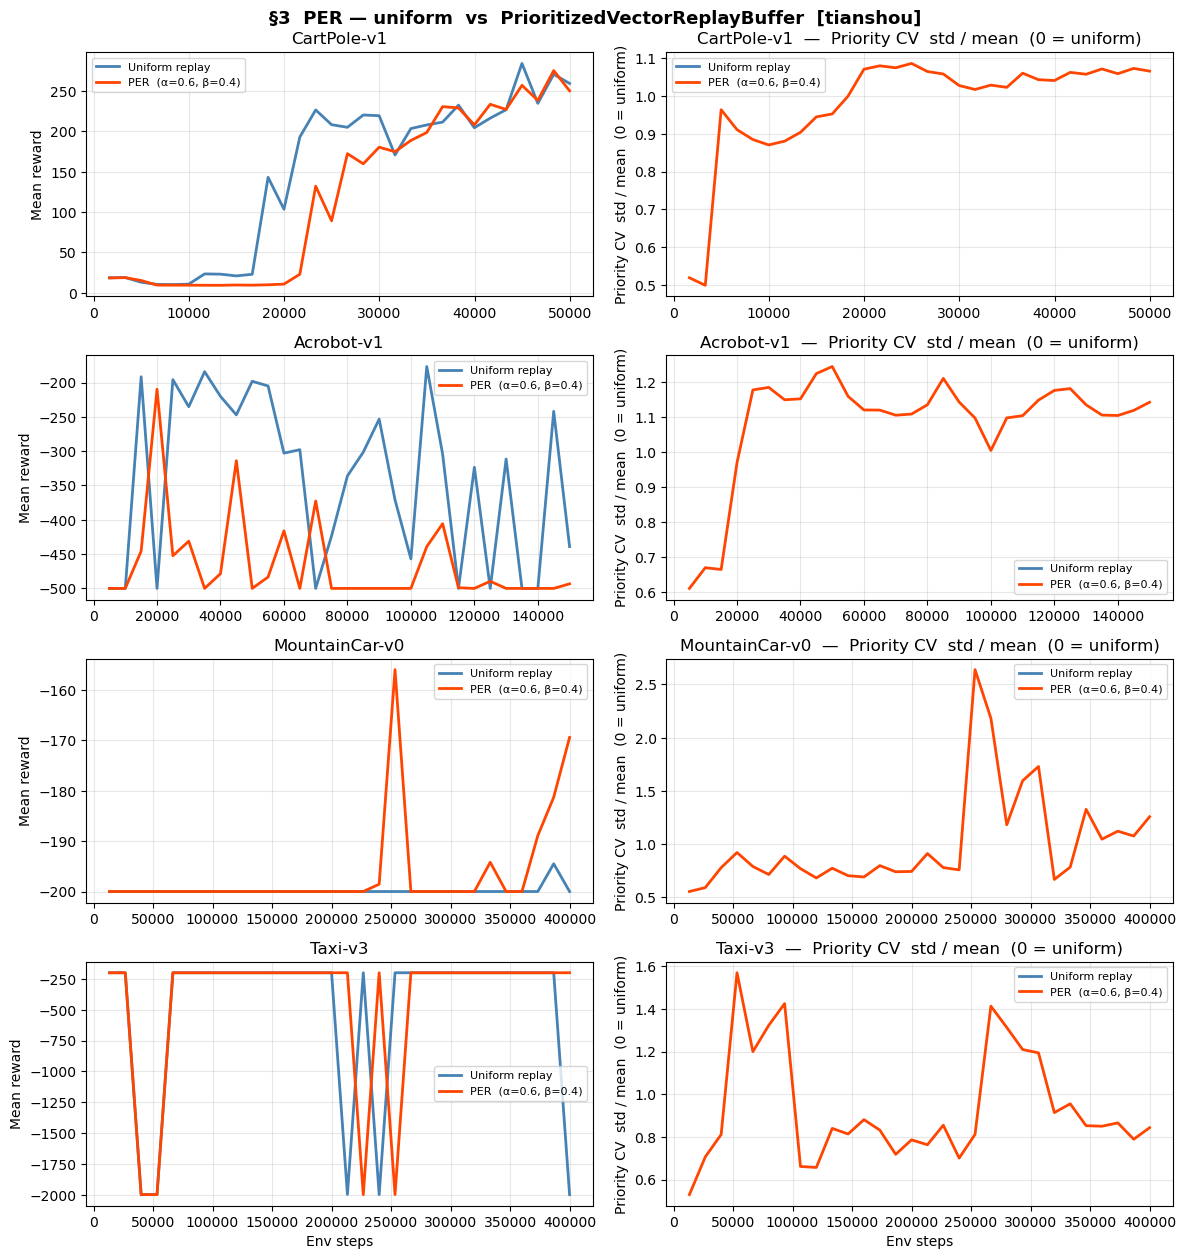

In [5]:
# ══════════════════════════════════════════════════════════════════════════════
# §3  PRIORITIZED EXPERIENCE REPLAY
# ══════════════════════════════════════════════════════════════════════════════
# Toggle: VectorReplayBuffer  vs  PrioritizedVectorReplayBuffer (α=0.6, β=0.4).
#
# Invariant (Schaul et al. 2016):
#   CV(priorities) = std(leaf_weights) / mean(leaf_weights)
#   Tianshou stores p^α in SegmentTree weight leaves.
#   Uniform buffer: all weights equal → CV ≈ 0.
#   PER: high-TD transitions accumulate higher weight → CV grows over training.
#
# Expected: faster initial learning on sparse-reward envs (MountainCar, Acrobot);
#   priority CV clearly > 0 and rising for PER model.

env_results = []
for env_id, meta in ENVS.items():
    print(f"  {env_id} ...", end=" ", flush=True)

    dqn_a, buf_a, tc_a, ec_a = make_objects(env_id, per_alpha=None, seed=SEED)
    dqn_b, buf_b, tc_b, ec_b = make_objects(env_id, per_alpha=0.6, per_beta=0.4, seed=SEED)

    rew_a, inv_a = train_epochs_ts(dqn_a, buf_a, tc_a, ec_a, env_id,
                                   meta["total_steps"], inv_priority_cv)
    rew_b, inv_b = train_epochs_ts(dqn_b, buf_b, tc_b, ec_b, env_id,
                                   meta["total_steps"], inv_priority_cv)

    env_results.append(dict(env_id=env_id,
                            rewards_a=rew_a, rewards_b=rew_b,
                            invs_a=inv_a,    invs_b=inv_b))
    print("done")

plot_section(
    "§3  PER — uniform  vs  PrioritizedVectorReplayBuffer  [tianshou]",
    env_results,
    label_a   = "Uniform replay",
    label_b   = "PER  (α=0.6, β=0.4)",
    inv_label = "Priority CV  std / mean  (0 = uniform)",
)

  CartPole-v1 ... done
  Acrobot-v1 ... done
  MountainCar-v0 ... done
  Taxi-v3 ... done


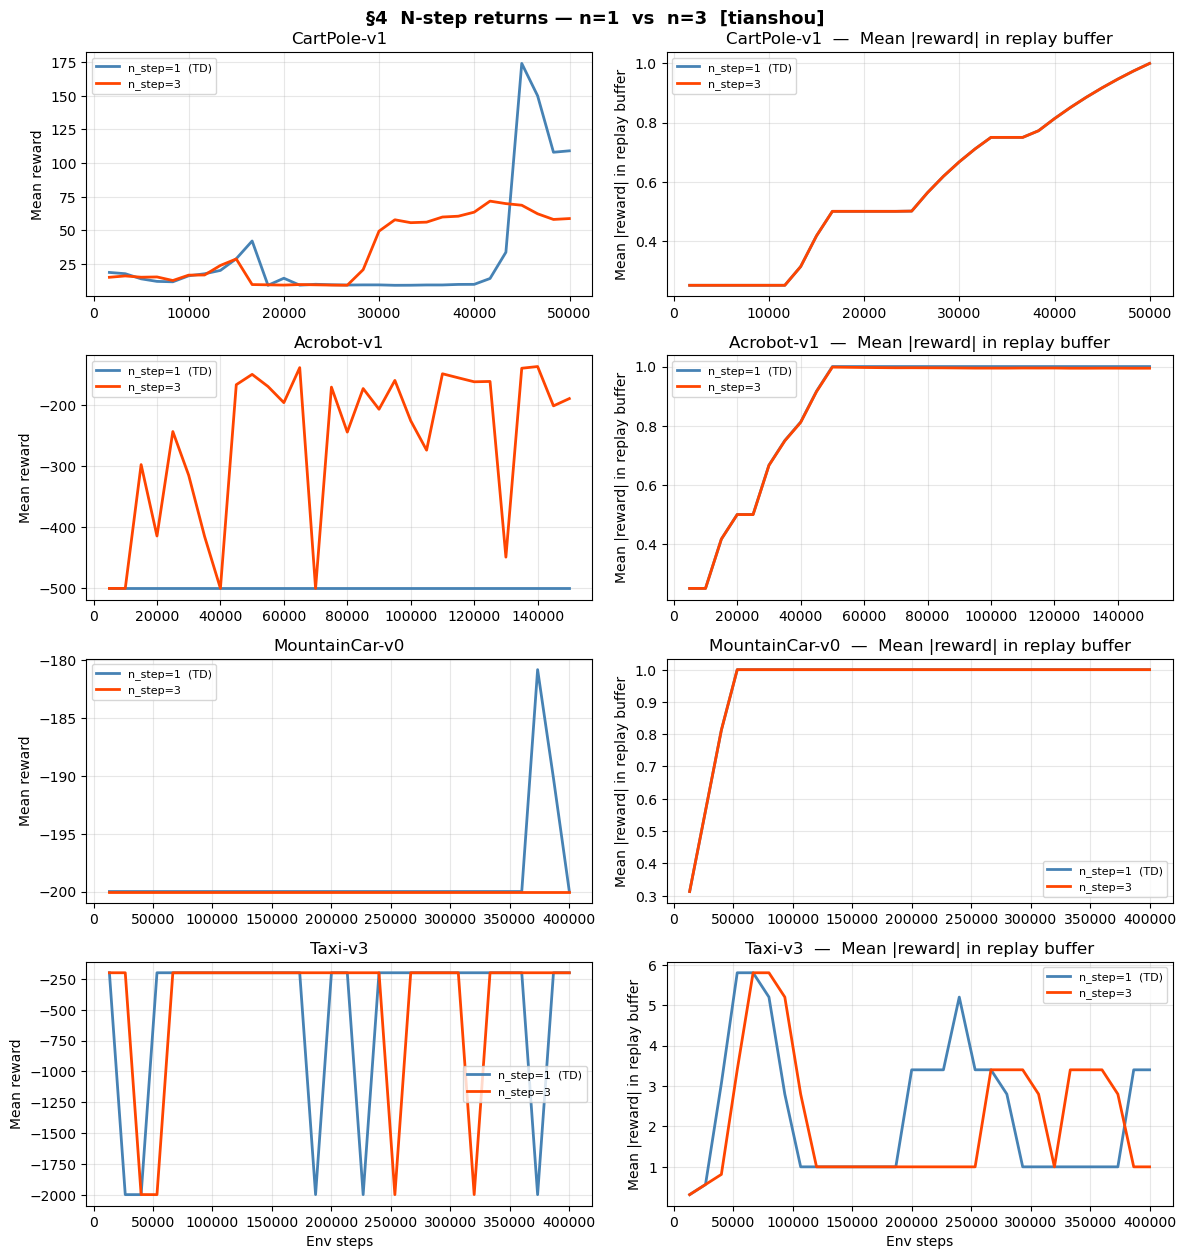

In [6]:
# ══════════════════════════════════════════════════════════════════════════════
# §4  N-STEP RETURNS
# ══════════════════════════════════════════════════════════════════════════════
# Toggle: n_step_return_horizon=1  vs  n_step_return_horizon=3.
# Tianshou computes n-step returns during _preprocess_batch (inside update()),
# using the standard buffer — no special wrapping required.
#
# Invariant (Sutton 1988):
#   mean |reward| in replay buffer.
#   n-step accumulates r_t + γr_{t+1} + γ²r_{t+2} before the Bellman target,
#   so effective |return| grows proportionally to n for constant-sign rewards.
#   NOTE: tianshou stores raw rewards; n-step accumulation happens inside
#   compute_nstep_return at sample time.  For constant-reward envs we can
#   verify the effect by comparing the mean absolute TD target instead.
#   We still plot mean |rew| for visual reference; the ratio effect is
#   visible indirectly through faster/slower Q-value growth.
#
# Expected: n-step curve leads on envs with delayed reward;
#   reward curves converge earlier for n=3.

env_results = []
for env_id, meta in ENVS.items():
    print(f"  {env_id} ...", end=" ", flush=True)

    dqn_a, buf_a, tc_a, ec_a = make_objects(env_id, n_step=1, seed=SEED)
    dqn_b, buf_b, tc_b, ec_b = make_objects(env_id, n_step=3, seed=SEED)

    rew_a, inv_a = train_epochs_ts(dqn_a, buf_a, tc_a, ec_a, env_id,
                                   meta["total_steps"], inv_mean_abs_reward)
    rew_b, inv_b = train_epochs_ts(dqn_b, buf_b, tc_b, ec_b, env_id,
                                   meta["total_steps"], inv_mean_abs_reward)

    env_results.append(dict(env_id=env_id,
                            rewards_a=rew_a, rewards_b=rew_b,
                            invs_a=inv_a,    invs_b=inv_b))
    print("done")

plot_section(
    "§4  N-step returns — n=1  vs  n=3  [tianshou]",
    env_results,
    label_a   = "n_step=1  (TD)",
    label_b   = "n_step=3",
    inv_label = "Mean |reward| in replay buffer",
)